In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sig
from scipy.fft import dct
from sklearn.mixture import GaussianMixture

plt.rcParams['figure.figsize'] = (10, 4)
np.set_printoptions(precision=3, suppress=True)

In [2]:
# La idea es que utilicen estas funciones, diccionarios, listas y variables sin modificar sus valores
fs = 16000

formantes = {
    'a': [750, 1300, 2500],
    'i': [300, 2300, 3000],
    'u': [350, 800, 2300],
}

anchos_BW = [80, 90, 120]

def sintetizar_vocal(formant_freqs, fs=16000, F0=120, duracion=0.6, bws=anchos_BW):
    N_x = int(duracion * fs)
    fuente = np.zeros(N_x)
    periodo = int(fs / F0)
    fuente[::periodo] = 1.0
    salida = fuente.copy()
    for f, bw in zip(formant_freqs, bws):
        r = np.exp(-np.pi * bw / fs)
        theta = 2 * np.pi * f / fs
        b = [1 - r*r]
        a = [1, -2*r*np.cos(theta), r*r]
        salida = sig.lfilter(b, a, salida)
    return salida / np.max(np.abs(salida))

def hz_to_mel(f):
    return 2595 * np.log10(1 + f / 700)

def mel_to_hz(m):
    return 700 * (10**(m / 2595) - 1)

def enmarcar(senial, fs, win_ms=25, hop_ms=10):
    L = int(round(win_ms * 1e-3 * fs))
    H = int(round(hop_ms * 1e-3 * fs))
    n_frames = 1 + (len(senial) - L) // H
    frames = np.stack([senial[i*H:i*H+L] for i in range(n_frames)])
    return frames * np.hamming(L)

def banco_mel(n_mels, n_fft, fs, f_min=80, f_max=None):
    if f_max is None:
        f_max = fs / 2
    puntos_mel = np.linspace(hz_to_mel(f_min), hz_to_mel(f_max), n_mels + 2)
    puntos_hz = mel_to_hz(puntos_mel)
    bins = np.floor(n_fft * puntos_hz / fs).astype(int)
    bins = np.clip(bins, 0, n_fft // 2)
    B = np.zeros((n_mels, n_fft//2 + 1))
    for m in range(1, n_mels + 1):
        izq, centro, der = bins[m-1], bins[m], bins[m+1]
        for k in range(izq, centro):
            B[m-1, k] = (k - izq) / max(centro - izq, 1)
        for k in range(centro, der):
            B[m-1, k] = (der - k) / max(der - centro, 1)
    return B

def mfcc_propio(senial, fs=16000, n_mfcc=13, n_mels=26, n_fft=512):
    senial_pe = np.append(senial[0], senial[1:] - 0.97 * senial[:-1])
    frames = enmarcar(senial_pe, fs)
    X = np.fft.rfft(frames, n=n_fft, axis=1)
    S = np.abs(X)**2
    B = banco_mel(n_mels, n_fft, fs)
    E = S @ B.T
    logE = np.log(E + 1e-10)
    return dct(logE, type=2, axis=1, norm='ortho')[:, :n_mfcc]

# Ejercicio 3

In [3]:
audio_a_ref = sintetizar_vocal(formantes['a'], F0=120, duracion=0.6) ### <-- COMPLETAR
audio_a_nivel = audio_a_ref * 0.6 ### <-- COMPLETAR
audio_a_pitch = sintetizar_vocal(formantes['a'], F0=200, duracion=0.6) ### <-- COMPLETAR
audio_i_ref = sintetizar_vocal(formantes['i'], F0=120, duracion=0.6) ### <-- COMPLETAR

seniales = {
    'a_ref': audio_a_ref, # Señal A
    'a_nivel': audio_a_nivel, # Señal B
    'a_pitch': audio_a_pitch, # Señal C
    'i_ref': audio_i_ref, # Señal D
}

### <-- COMPLETAR
matrices_mfcc = {
    'a_ref': mfcc_propio(seniales['a_ref']), 
    'a_nivel': mfcc_propio(seniales['a_nivel']),
    'a_pitch': mfcc_propio(seniales['a_pitch']),
    'i_ref': mfcc_propio(seniales['i_ref']),
}

### <-- COMPLETAR
promedios_temporales = {
    'a_ref': np.mean(matrices_mfcc['a_ref'], axis=0), 
    'a_nivel': np.mean(matrices_mfcc['a_nivel'], axis=0),
    'a_pitch': np.mean(matrices_mfcc['a_pitch'], axis=0),
    'i_ref': np.mean(matrices_mfcc['i_ref'], axis=0),
}

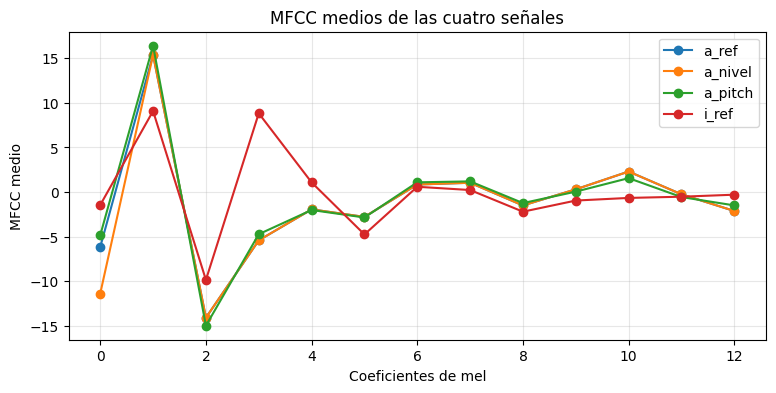

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
for nombre, vec_medio in promedios_temporales.items():
    ax.plot(np.arange(len(vec_medio)), vec_medio, marker='o', label=nombre)
ax.set_xlabel('Coeficientes de mel') ### <-- COMPLETAR
ax.set_ylabel('MFCC medio')
ax.set_title('MFCC medios de las cuatro señales')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [5]:
def distancia_mfcc(a, b, incluir_c0=True):
    ### <-- COMPLETAR FUNCIÓN
    if incluir_c0:
        resta = np.linalg.norm(a-b)
    else:
        resta = np.linalg.norm(a[1:]-b[1:])
    return resta 

referencia = promedios_temporales['a_ref']

for nombre in ['a_nivel', 'a_pitch', 'i_ref']:
    d_13 = distancia_mfcc(promedios_temporales['a_ref'], promedios_temporales[nombre], incluir_c0=True) ### <-- COMPLETAR
    d_12 = distancia_mfcc(promedios_temporales['a_ref'], promedios_temporales[nombre], incluir_c0=False) ### <-- COMPLETAR
    print(f'Para {nombre} obtenemos: {d_13:.2f} (con c0) y {d_12:.2f} (sin c0)')

Para a_nivel obtenemos: 5.21 (con c0) y 0.00 (sin c0)
Para a_pitch obtenemos: 2.31 (con c0) y 1.90 (sin c0)
Para i_ref obtenemos: 17.62 (con c0) y 16.98 (sin c0)


# Ejercicio 4

In [33]:
audio_a_100 = sintetizar_vocal(formantes['a'], F0=100, duracion=0.6) ### <-- COMPLETAR (señal de 100 Hz para /a/)
audio_a_200 = sintetizar_vocal(formantes['a'], F0=200, duracion=0.6) ### <-- COMPLETAR (señal de 200 Hz para /a/)
audio_a_100_bajo = audio_a_100 * 0.25 ### <-- COMPLETAR (señal adicional)
audio_i_100 = sintetizar_vocal(formantes['i'], F0=100, duracion=0.6) ### <-- COMPLETAR (señal adicional)

mfcc_a_100 = mfcc_propio(audio_a_100) ### <-- COMPLETAR
mfcc_a_200 = mfcc_propio(audio_a_200) ### <-- COMPLETAR
mfcc_a_100_bajo = mfcc_propio(audio_a_100_bajo) ### <-- COMPLETAR
mfcc_i_100 = mfcc_propio(audio_i_100) ### <-- COMPLETAR

# 13 y 12 corresponden a la cantidad de MFCC considerados
X_entrenamiento_13 = np.vstack([mfcc_a_100, mfcc_a_200]) ### <-- COMPLETAR
X_entrenamiento_12 = np.vstack([mfcc_a_100[:, 1:], mfcc_a_200[:, 1:]]) ### <-- COMPLETAR

In [32]:
def crear_gmm():
    ### COMPLETAR LO QUE FALTA
    return GaussianMixture(n_components=2, covariance_type='diag', init_params='random_from_data', n_init=5, max_iter=300, reg_covar=1e-3, random_state=0) 

modelo_13 = crear_gmm()
modelo_13.fit(X_entrenamiento_13) ### <-- COMPLETAR

modelo_12 = crear_gmm()
modelo_12.fit(X_entrenamiento_12) ### <-- COMPLETAR

for nombre, C in {'a_100': mfcc_a_100, 'a_200': mfcc_a_200}.items():
    responsabilidades = modelo_13.predict_proba(C) ### <-- COMPLETAR
    responsabilidades_medias = np.mean(responsabilidades, axis=0) ### <-- COMPLETAR
    print(f'{nombre}: {responsabilidades_medias}')

a_100: [1. 0.]
a_200: [0. 1.]


### Interpretación
* Le metimos al modelo 2 clases (él no sabe que son clases)
* Le pediste que haga dos gaussianas (M=2)
* Las clases son claramente distinguibles pues está considerarndo F0 (1era componente de MFCC)
* En consecuencia, el modelo hace dos gaussianas

Acordate que `predict_proba` lo que hace es obtener: $p( Z = m  \mid \mathbf y)$'

In [42]:
def log_verosimilitud_media(modelo, C, incluir_c0=True):
    ### <-- COMPLETAR FUNCIÓN
    if incluir_c0 == False:
        C = C[:, 1:]
    
    #Esto serviría si los modelos fueran una lista:
    #log_likelihoods_mean = [modelo_.score(C) for modelo_ in modelo]
    #Como no lo son:
    log_likelihoods_mean = modelo.score(C) #score ya devuelve la media por sample
    return log_likelihoods_mean 

casos = {
    'a_100': mfcc_a_100,
    'a_200': mfcc_a_200,
    'a_100_bajo': mfcc_a_100_bajo,
    'i_100': mfcc_i_100,
}

for nombre, C in casos.items():
    ell_13 = log_verosimilitud_media(modelo_13, C, incluir_c0=True) ### <-- COMPLETAR
    ell_12 = log_verosimilitud_media(modelo_12, C, incluir_c0=False) ### <-- COMPLETAR
    print(f'Para {nombre} obtenemos: {ell_13:.2f} (con c0) y {ell_12:.2f} (sin c0)')

Para a_100 obtenemos: 31.80 (con c0) y 29.41 (sin c0)
Para a_200 obtenemos: 28.32 (con c0) y 26.46 (sin c0)
Para a_100_bajo obtenemos: -63059.60 (con c0) y 29.41 (sin c0)
Para i_100 obtenemos: -66572.91 (con c0) y -65959.34 (sin c0)


### Interpretación:
Primero, acordate que estamos evaluando

$$
p(\mathbf y, \theta)
=
\sum_{m=1}^{2}
\omega_{m}
\mathcal N(
\mathbf y;
\boldsymbol\mu_{m},
\boldsymbol\Sigma_{m}
).
$$
Es decir, que tan posible es que el dato sea generado por el modelo GMM $\theta$

* Las primeras dos log-verosimilitudes son altas, es esperable pues entrenamos con esas mismas señales
* El tercero es interesante: si considerás la energía no es posible pero si sacamos la energía, el modelo dice que es probable y esa probabilidad coincide con la primera porque, en escencia, son la misma señal
* Sobre la "i": bueno, no encaja en ningún lado de ninguna forma pues no es parte del entrenamiento